**LAB 2 - Linear and polynomial regression**

## **Task 1: Load first a subset of the data to be analyzed**


In [2]:
import math
from idlelib.colorizer import color_config
from locale import str


def load_csv(filename):
    data = []

    with open(filename, "r", encoding='utf-8') as file:
        header = file.readline().strip().split(",")[1:]
        for line in file:
            print(line)
            values = line.strip().split(",")
            values = values[1:]  # Remove first column

            age = int(values[0])
            income = float(values[1])

            data.append([age, income])
    return header, data

dataSs = load_csv("datasets/lab2/inc_subset.csv")
print(dataSs)

4,20,129.24285714285713

5,21,146.3095238095238

6,22,164.0

7,23,182.3952380952381

8,24,202.0761904761905

9,25,224.13809523809522

10,26,242.61904761904762

11,27,258.2333333333333

12,28,271.52857142857147

13,29,282.8333333333333

14,30,291.06666666666666

15,31,297.6047619047619

16,32,305.7095238095238

17,33,312.83809523809526

18,34,319.252380952381

19,35,327.87619047619046

20,36,335.7238095238095

21,37,343.14761904761906

22,38,354.1714285714286

23,39,362.8285714285714

24,40,371.0952380952381

25,41,379.6714285714286

26,42,386.147619047619

27,43,391.447619047619

28,44,400.34285714285716

29,45,405.5

30,46,408.8619047619048

31,47,414.06666666666666

32,48,415.0904761904762

33,49,416.2523809523809

(['age', '2020'], [[20, 129.24285714285713], [21, 146.3095238095238], [22, 164.0], [23, 182.3952380952381], [24, 202.0761904761905], [25, 224.13809523809522], [26, 242.61904761904762], [27, 258.2333333333333], [28, 271.52857142857147], [29, 282.8333333333333], [30, 291.066

Debugger: More convenient for finding errors and inspecting how variables change during execution, especially inside loops or complex functions.

Printout: More convenient for quickly checking the final or intermediate output, especially when I want to see many values at once.

## **Task 2: Linear regression on a data subset.**

- Perform the linear regression on the provided dataset

In [3]:
import pandas as pd

header, values = dataSs
df = pd.DataFrame(values, columns=header)

train = df.sample(frac=0.8, random_state=42)
validation = df.drop(train.index)

print(train)
print(validation)


    age        2020
27   47  414.066667
15   35  327.876190
23   43  391.447619
17   37  343.147619
8    28  271.528571
9    29  282.833333
28   48  415.090476
24   44  400.342857
12   32  305.709524
0    20  129.242857
4    24  202.076190
16   36  335.723810
5    25  224.138095
13   33  312.838095
11   31  297.604762
22   42  386.147619
1    21  146.309524
2    22  164.000000
25   45  405.500000
3    23  182.395238
21   41  379.671429
26   46  408.861905
18   38  354.171429
29   49  416.252381
    age        2020
6    26  242.619048
7    27  258.233333
10   30  291.066667
14   34  319.252381
19   39  362.828571
20   40  371.095238


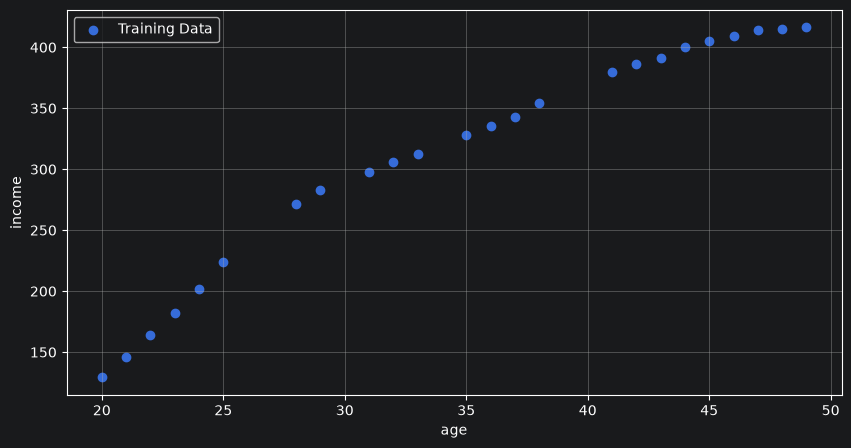

In [4]:
import matplotlib.pyplot as plt
x = train["age"]
y = train["2020"]

plt.figure(figsize=(10, 5))
plt.scatter(x, y, label="Training Data")
plt.xlabel("age")
plt.ylabel("income")
plt.grid()
plt.legend()
plt.show()


Predicting is just $\hat y = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + ... + \theta_n x_n$. We measure how wrong a given $\theta$ is with the **Mean Squared Error**:

$$J(\boldsymbol\theta) = \text{MSE}(\boldsymbol\theta) = \frac{1}{m}\sum_{i=1}^{m}\left(\boldsymbol\theta^\top \mathbf{x}^{(i)} - y^{(i)}\right)^2 = \frac{1}{m}\lVert \mathbf{X}\boldsymbol\theta - \mathbf{y} \rVert^2$$
Because $J$ is a sum of squares of a *linear* function of $\boldsymbol\theta$, it's a **convex,
bowl-shaped function** of $\boldsymbol\theta$

To find the minimum of a convex bowl, we take its **gradient** with respect to
$\boldsymbol\theta$ and set it to zero (the bottom of a bowl is exactly where the slope is flat
in every direction):

$$\nabla_{\boldsymbol\theta}\, J(\boldsymbol\theta) = \frac{2}{m}\mathbf{X}^\top(\mathbf{X}\boldsymbol\theta - \mathbf{y}) = \mathbf{0}$$

Multiplying both sides by $m/2$ and expanding:

$$\mathbf{X}^\top \mathbf{X}\boldsymbol\theta = \mathbf{X}^\top \mathbf{y}$$

If $\mathbf{X}^\top \mathbf{X}$ is invertible, we can solve directly for $\boldsymbol\theta$:

$$\boxed{\hat{\boldsymbol\theta} = (\mathbf{X}^\top \mathbf{X})^{-1}\mathbf{X}^\top \mathbf{y}}$$

This is the **Normal Equation**.

In [5]:
import numpy as np
x = train["age"].values
y = train["2020"].values

X_b = np.c_[np.ones((len(x), 1)), x] # add x0 = 1 to each instance
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
print(theta_best)

# Making predictions:
x_vals = validation["age"].values
y_vals = validation["2020"].values
X_vals_b = np.c_[np.ones((len(x_vals), 1)), x_vals]
y_preds = X_vals_b @ theta_best
print(y_preds)


[-25.66207948   9.66968546]
[225.74974239 235.41942784 264.42848421 303.10722604 351.45565332
 361.12533878]


Predict the values for the validation dataset and print both the real values and the predicted ones

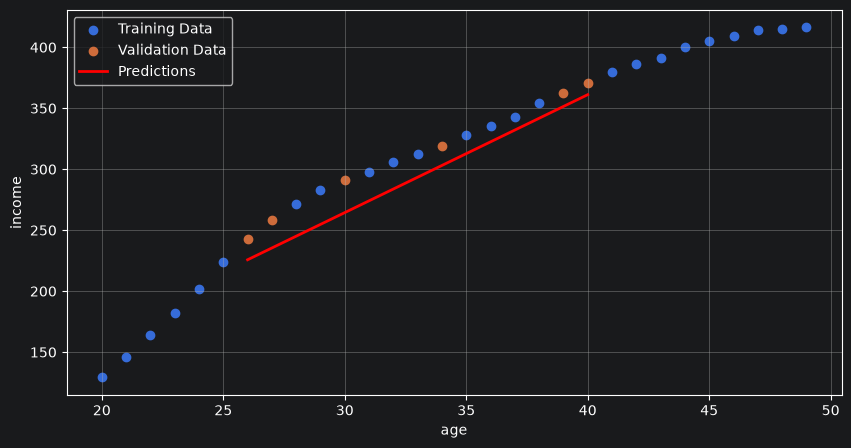

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.scatter(x, y, label="Training Data")
plt.scatter(x_vals, y_vals, label="Validation Data")
plt.xlabel("age")
plt.ylabel("income")
plt.plot(x_vals, y_preds, "r-", linewidth=2, label="Predictions")
plt.grid()
plt.legend()
plt.show()


Evaluate the model using MSE, implement the function that evaluates each of the real values
against the predicted values

In [24]:
def mse(y_preds, y_reals):
    suma = 0
    m = len(y_preds)
    for p,r in zip(y_preds, y_reals):
        op = (p - r)**2
        suma += op
    return (1/m) * suma
print(mse(y_preds, y_vals))

334.0081154431347


MSE = Mean(Squared Errors), so it calculates the average of the squared errors between the predicted and actual values. Therefore, its value is expressed in squared units (difficult to interpret directly).

By taking the square root of the MSE (RMSE), it will be expressed in the original units.

In [25]:
import math
RMSE = math.sqrt(mse(y_preds, y_vals))
print(RMSE)

18.275888909794094


The RMSE is 18.275888909794094, meaning that the model has a typical prediction error of that number income units. That means that if the real value is 100, it could be between 81.7 and 118.3

I think linear regression is a good call for this problem, because the target variable (income) is continuous.

EXTRA: Implementing Gradient Descent
We have from before that $\nabla_{\boldsymbol\theta}\text{MSE}(\boldsymbol\theta) = \frac{2}{m}\mathbf X^\top(\mathbf X\boldsymbol\theta - \mathbf y)$
— the exact same expression we set to zero to *derive* the Normal Equation. This time, instead
of solving algebraically for where it equals zero, we just repeatedly walk downhill along it.

In [50]:
x = train[["age"]].values
y = train[["2020"]].values

X_b = np.c_[np.ones((len(x), 1)), x] # add x0 = 1 to each instance

eta = 0.0001          # learning rate
n_epochs = 1000000
m = len(train)

np.random.seed(42)
theta = np.random.randn(2, 1)   # random initialization -- we have to start somewhere

for epoch in range(n_epochs):
    gradients = 2 / m * X_b.T @ (X_b @ theta - y)
    theta = theta - eta * gradients

print(theta)

[[-25.66202066]
 [  9.66968388]]


KeyboardInterrupt: 

Exception ignored in: <function WeakKeyDictionary.__init__.<locals>.remove at 0x0000020C57BCA3E0>
Traceback (most recent call last):
  File "C:\Python313\Lib\weakref.py", line 369, in remove
    def remove(k, selfref=ref(self)):
KeyboardInterrupt: 


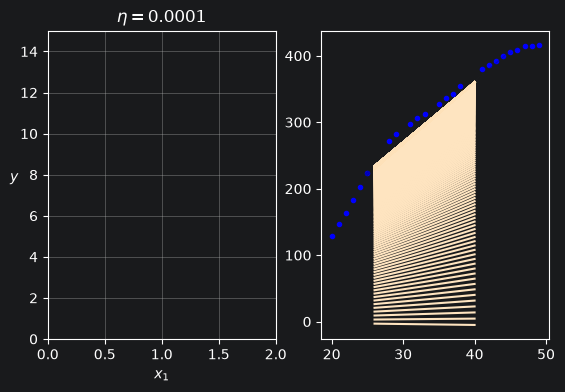

In [47]:
import matplotlib as mpl
def plot_gradient_descent(theta, eta):
    m = len(X_b)
    plt.plot(x, y, "b.")
    x_vals = validation[["age"]].values
    y_vals = validation["2020"].values
    X_vals_b = np.c_[np.ones((len(x_vals), 1)), x_vals]
    n_epochs = 1000000
    n_shown = 20                # only plot the first 20 steps, to keep the figure readable
    theta_path = []
    for epoch in range(n_epochs):
        if epoch < n_shown:
            y_predict = X_vals_b @ theta
            color = mpl.colors.rgb2hex(plt.cm.OrRd(epoch / n_shown + 0.15))
            plt.plot(x_vals, y_predict, linestyle="solid", color=color)
        gradients = 2 / m * X_b.T @ (X_b @ theta - y)
        theta = theta - eta * gradients
        theta_path.append(theta)
    plt.xlabel("$x_1$")
    plt.axis([0, 2, 0, 15])
    plt.grid()
    plt.title(fr"$\eta = {eta}$")
    return theta_path

np.random.seed(42)
theta = np.random.randn(2, 1)   # same random starting point for all three runs

plt.figure(figsize=(10, 4))
plt.subplot(131)
plot_gradient_descent(theta, eta=0.0001)
plt.ylabel("$y$", rotation=0)
plt.subplot(132)
theta_path_bgd = plot_gradient_descent(theta, eta=0.00001)   # we'll reuse this path later
plt.gca().axes.yaxis.set_ticklabels([])
plt.subplot(133)
plt.gca().axes.yaxis.set_ticklabels([])
plot_gradient_descent(theta, eta=0.00005)
plt.show()


In [64]:
x = train[["age"]].values
y = train[["2020"]].values

X_b = np.c_[np.ones((len(x), 1)), x] # add x0 = 1 to each instance
n_epochs = 5000
t0, t1 = 0.01, 50   # learning schedule hyperparameters

def learning_schedule(t):
    return t0 / (t + t1)

np.random.seed(42)
theta = np.random.randn(2, 1)   # random initialization
theta_path_sgd = []              # we'll reuse this path later, to compare against the others

for epoch in range(n_epochs):
    for iteration in range(m):
        random_index = np.random.randint(m)
        xi = X_b[random_index : random_index + 1]
        yi = y[random_index : random_index + 1]
        gradients = 2 * xi.T @ (xi @ theta - yi)   # single instance -> no dividing by m here
        eta = learning_schedule(epoch * m + iteration)
        theta = theta - eta * gradients
        theta_path_sgd.append(theta)

print(theta)


[[0.50732062]
 [8.97228917]]


In [66]:
from math import ceil

n_epochs = 50
minibatch_size = 20
n_batches_per_epoch = ceil(m / minibatch_size)

t0, t1 = 200, 1000   # learning schedule hyperparameters -- different scale than SGD's above
def learning_schedule(t):
    return t0 / (t + t1)

np.random.seed(42)
theta = np.random.randn(2, 1)
theta_path_mgd = []   # we'll reuse this path too, for the final comparison plot

for epoch in range(n_epochs):
    shuffled_indices = np.random.permutation(m)     # reshuffle the data every epoch
    X_b_shuffled = X_b[shuffled_indices]
    y_shuffled = y[shuffled_indices]
    for iteration in range(n_batches_per_epoch):
        idx = iteration * minibatch_size
        xi = X_b_shuffled[idx : idx + minibatch_size]
        yi = y_shuffled[idx : idx + minibatch_size]
        gradients = 2 / minibatch_size * xi.T @ (xi @ theta - yi)
        eta = learning_schedule(iteration)
        theta = theta - eta * gradients
        theta_path_mgd.append(theta)

print(theta)

[[-9.98160405e+235]
 [-3.19456418e+237]]


Task 3: Linear regression on full dataset.

In [68]:
def load_csv(filename):
    data = []

    with open(filename, "r", encoding='utf-8') as file:
        header = file.readline().strip().split(",")[1:]
        for line in file:
            values = line.strip().split(",")[1:]

            region = values[0][3:]
            age = int(values[1].replace(" years", "").replace("100+","101"))
            income = float(values[2])
            # data.append(values)
            data.append([region, age, income])
    return header, data

header, dataset = load_csv("datasets/lab2/inc_utf.csv")
print(header, dataset)

['region', 'age', '2020'] [['Stockholm county', 16, 4.6], ['Stockholm county', 17, 8.8], ['Stockholm county', 18, 17.8], ['Stockholm county', 19, 52.5], ['Stockholm county', 20, 112.0], ['Stockholm county', 21, 127.9], ['Stockholm county', 22, 147.1], ['Stockholm county', 23, 167.9], ['Stockholm county', 24, 191.8], ['Stockholm county', 25, 225.2], ['Stockholm county', 26, 257.1], ['Stockholm county', 27, 285.3], ['Stockholm county', 28, 308.6], ['Stockholm county', 29, 328.0], ['Stockholm county', 30, 344.9], ['Stockholm county', 31, 354.9], ['Stockholm county', 32, 364.1], ['Stockholm county', 33, 373.6], ['Stockholm county', 34, 385.3], ['Stockholm county', 35, 395.8], ['Stockholm county', 36, 405.9], ['Stockholm county', 37, 421.0], ['Stockholm county', 38, 432.8], ['Stockholm county', 39, 450.1], ['Stockholm county', 40, 456.9], ['Stockholm county', 41, 468.7], ['Stockholm county', 42, 475.4], ['Stockholm county', 43, 488.6], ['Stockholm county', 44, 508.0], ['Stockholm county', 4

In [69]:
import pandas as pd

def mean(list):
    sum = 0.
    for i in list:
        sum += i
    sum = sum / len(list)
    return sum

df = pd.DataFrame(dataset, columns=header)

def mean_income_by_age(data):
    l_ages = []

    for age in data["age"]:
        if age not in l_ages:
            l_ages.append(age)

    dicc = {}
    for age, inc in zip(data["age"], data["2020"]):
        if age not in dicc:
            dicc[age] = [inc]
        else:
            dicc[age].append(inc)

    for age, incs in dicc.items():
        dicc[age] = mean(incs)
    return dicc

mean_inc_by_age = mean_income_by_age(df)
print(mean_inc_by_age)

{16: 5.471428571428571, 17: 10.552380952380954, 18: 22.390476190476193, 19: 65.37619047619049, 20: 129.2428571428571, 21: 146.3095238095238, 22: 164.00000000000003, 23: 182.39523809523806, 24: 202.0761904761905, 25: 224.13809523809527, 26: 242.61904761904762, 27: 258.23333333333335, 28: 271.5285714285714, 29: 282.8333333333333, 30: 291.0666666666667, 31: 297.60476190476186, 32: 305.70952380952383, 33: 312.8380952380953, 34: 319.2523809523809, 35: 327.87619047619046, 36: 335.7238095238095, 37: 343.14761904761906, 38: 354.1714285714285, 39: 362.8285714285715, 40: 371.0952380952381, 41: 379.6714285714285, 42: 386.147619047619, 43: 391.447619047619, 44: 400.3428571428571, 45: 405.5000000000001, 46: 408.86190476190467, 47: 414.06666666666666, 48: 415.09047619047635, 49: 416.2523809523809, 50: 411.6190476190476, 51: 412.3333333333333, 52: 410.41428571428577, 53: 413.46190476190486, 54: 406.952380952381, 55: 402.3238095238096, 56: 399.22380952380956, 57: 392.8666666666667, 58: 387.52857142857

In [70]:
import pandas as pd

header = ["age", "mean_income"]
values = mean_inc_by_age.items()

df = pd.DataFrame(values, columns=header)

train = df.sample(frac=0.8, random_state=42)
validation = df.drop(train.index)

print(train)
print(validation)


    age  mean_income
78   94    192.75714
0    16      5.47143
68   84    213.80476
22   38    354.17143
12   28    271.52857
..  ...          ...
81   97    185.19524
75   91    199.92381
57   73    254.23810
32   48    415.09048
80   96    186.75238

[68 rows x 2 columns]
    age  mean_income
1    17     10.55238
2    18     22.39048
14   30    291.06667
20   36    335.72381
21   37    343.14762
23   39    362.82857
29   45    405.50000
37   53    413.46190
51   67    332.16667
52   68    316.34286
59   75    242.47619
60   76    237.39048
63   79    225.30952
71   87    205.40000
73   89    203.94286
74   90    200.82381
79   95    194.10000


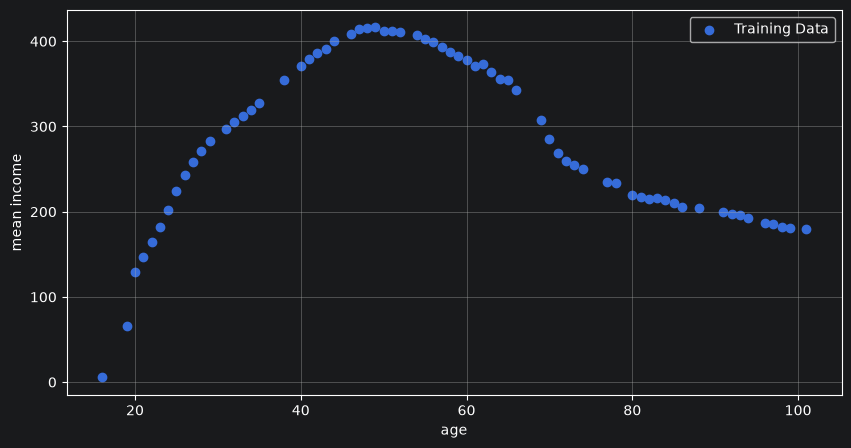

In [71]:
import matplotlib.pyplot as plt
x = train["age"]
y = train["mean_income"]

plt.figure(figsize=(10, 5))
plt.scatter(x, y, label="Training Data")
plt.xlabel("age")
plt.ylabel("mean income")
plt.grid()
plt.legend()
plt.show()


In [14]:
import numpy as np
x = train["age"].values
y = train["mean_income"].values

X_b = np.c_[np.ones((len(x), 1)), x] # add x0 = 1 to each instance
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
print(theta_best)

# Making predictions:
x_vals = validation["age"].values
y_vals = validation["mean_income"].values
X_vals_b = np.c_[np.ones((len(x_vals), 1)), x_vals]
y_preds = X_vals_b @ theta_best
print(y_preds)

[317.77643337  -0.58244332]
[307.874897   307.29245369 300.3031339  296.808474   296.22603069
 295.06114406 291.56648416 286.90693763 278.75273121 278.1702879
 274.09318468 273.51074137 271.76341142 267.10386489 265.93897826
 265.35653495 262.44431837]


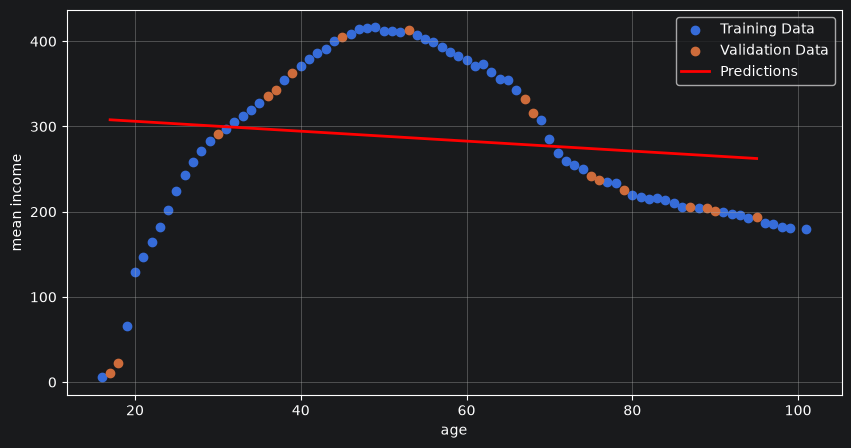

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.scatter(x, y, label="Training Data")
plt.scatter(x_vals, y_vals, label="Validation Data")
plt.xlabel("age")
plt.ylabel("mean income")
plt.plot(x_vals, y_preds, "r-", linewidth=2, label="Predictions")
plt.grid()
plt.legend()
plt.show()

In [16]:
def mse(y_preds, y_reals):
    suma = 0
    m = len(y_preds)
    for p,r in zip(y_preds, y_reals):
        op = (p - r)**2
        suma += op
    return (1/m) * suma
print(mse(y_preds, y_vals))

13659.962704721422


In [17]:
import math
RMSE = math.sqrt(mse(y_preds, y_vals))
print(RMSE)

116.87584311876181


Task 4: Reflections

What differences can you see from the graphs, predicted values and MSE scores from both linear regressions?

The main difference is that the deviation of the first graph is around 18 and in the second it is around 116 points, that means that is almost 7 times worst.

 How do you think this analysis can be improved considering the obtained results of task 3?
 Applying polynomial regression, adding more features/ transform the features or different models


Task 5: Polynomial regression with hyperparameter tunning

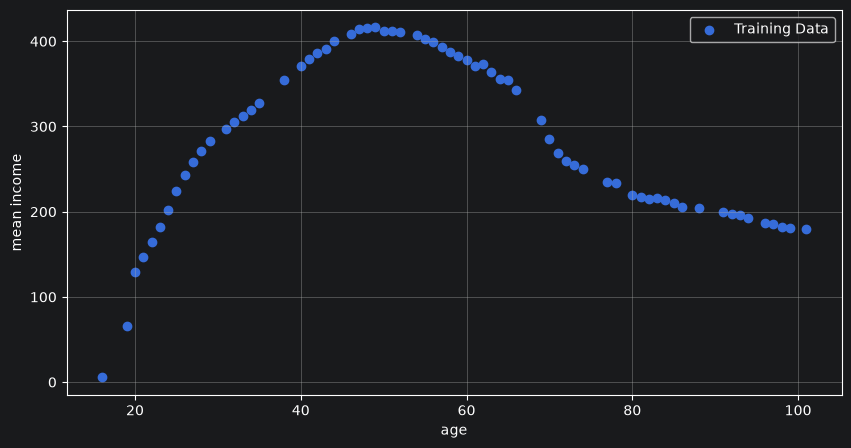

In [99]:
import matplotlib.pyplot as plt
x = train["age"]
y = train["mean_income"]

plt.figure(figsize=(10, 5))
plt.scatter(x, y, label="Training Data")
plt.xlabel("age")
plt.ylabel("mean income")
plt.grid()
plt.legend()
plt.show()


In [100]:
from sklearn.preprocessing import PolynomialFeatures

x = train[["age"]].values
y = train[["mean_income"]].values

poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly_features.fit_transform(x)
print(x[0])
print(X_poly)

[94]
[[   94.  8836.]
 [   16.   256.]
 [   84.  7056.]
 [   38.  1444.]
 [   28.   784.]
 [   98.  9604.]
 [   26.   676.]
 [   34.  1156.]
 [   20.   400.]
 [   82.  6724.]
 [   56.  3136.]
 [   63.  3969.]
 [   51.  2601.]
 [   88.  7744.]
 [   71.  5041.]
 [   70.  4900.]
 [   49.  2401.]
 [   93.  8649.]
 [   58.  3364.]
 [   65.  4225.]
 [   27.   729.]
 [   46.  2116.]
 [   55.  3025.]
 [   44.  1936.]
 [   25.   625.]
 [   80.  6400.]
 [   21.   441.]
 [   61.  3721.]
 [   47.  2209.]
 [   50.  2500.]
 [   60.  3600.]
 [  101. 10201.]
 [   32.  1024.]
 [   81.  6561.]
 [   23.   529.]
 [   85.  7225.]
 [   72.  5184.]
 [   35.  1225.]
 [   86.  7396.]
 [   41.  1681.]
 [   69.  4761.]
 [   29.   841.]
 [   77.  5929.]
 [   19.   361.]
 [   33.  1089.]
 [   54.  2916.]
 [   24.   576.]
 [   83.  6889.]
 [   22.   484.]
 [   52.  2704.]
 [   92.  8464.]
 [   78.  6084.]
 [   66.  4356.]
 [   62.  3844.]
 [   99.  9801.]
 [   31.   961.]
 [   43.  1849.]
 [   57.  3249.]
 [   74. 

In [101]:
from sklearn.linear_model import LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)
lin_reg.intercept_, lin_reg.coef_

(array([-110.32331786]), array([[17.130005  , -0.15145074]]))

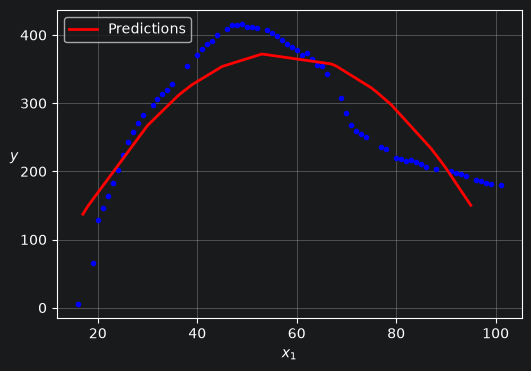

In [102]:
X_new = validation[["age"]].values
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

plt.figure(figsize=(6, 4))
plt.plot(x, y, "b.")
plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper left")
plt.grid()
plt.show()

In [103]:
x_vals = validation["age"].values
y_vals = validation["mean_income"].values

def mse(y_preds, y_reals):
    suma = 0
    m = len(y_preds)
    for p,r in zip(y_preds, y_reals):
        op = (p - r)**2
        suma += op
    return (1/m) * suma
print(mse(y_new, y_vals))

[3676.91454584]


In [104]:
import math
RMSE = math.sqrt(mse(y_new, y_vals)[0])
print(RMSE)

60.63756711674507


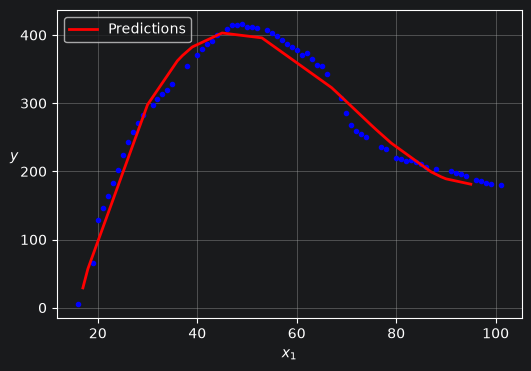

In [105]:
x = train[["age"]].values
y = train[["mean_income"]].values

poly_features = PolynomialFeatures(degree=3, include_bias=False)
X_poly = poly_features.fit_transform(x)

lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)

X_new = validation[["age"]].values
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

plt.figure(figsize=(6, 4))
plt.plot(x, y, "b.")
plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper left")
plt.grid()
plt.show()

In [106]:
def mse(y_preds, y_reals):
    suma = 0
    m = len(y_preds)
    for p,r in zip(y_preds, y_reals):
        op = (p - r)**2
        suma += op
    return (1/m) * suma
print(mse(y_new, y_vals))

[335.73992547]


In [107]:
import math
RMSE = math.sqrt(mse(y_new, y_vals)[0])
print(RMSE)

18.32320729203499


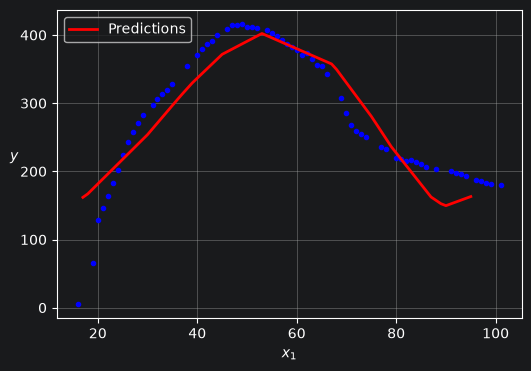

In [111]:
x = train[["age"]].values
y = train[["mean_income"]].values

poly_features = PolynomialFeatures(degree=5, include_bias=False)
X_poly = poly_features.fit_transform(x)

lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)

X_new = validation[["age"]].values
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

plt.figure(figsize=(6, 4))
plt.plot(x, y, "b.")
plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper left")
plt.grid()
plt.show()

In [112]:
def mse(y_preds, y_reals):
    suma = 0
    m = len(y_preds)
    for p,r in zip(y_preds, y_reals):
        op = (p - r)**2
        suma += op
    return (1/m) * suma
print(mse(y_new, y_vals))

[3636.0359778]


In [113]:
import math
RMSE = math.sqrt(mse(y_new, y_vals)[0])
print(RMSE)

60.29955205309897


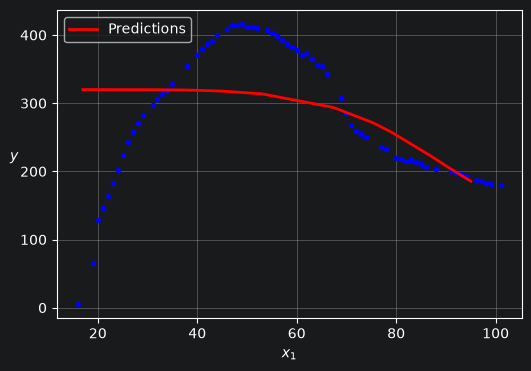

In [114]:
x = train[["age"]].values
y = train[["mean_income"]].values

poly_features = PolynomialFeatures(degree=8, include_bias=False)
X_poly = poly_features.fit_transform(x)

lin_reg = LinearRegression()
lin_reg.fit(X_poly, y)

X_new = validation[["age"]].values
X_new_poly = poly_features.transform(X_new)
y_new = lin_reg.predict(X_new_poly)

plt.figure(figsize=(6, 4))
plt.plot(x, y, "b.")
plt.plot(X_new, y_new, "r-", linewidth=2, label="Predictions")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper left")
plt.grid()
plt.show()

In [115]:
def mse(y_preds, y_reals):
    suma = 0
    m = len(y_preds)
    for p,r in zip(y_preds, y_reals):
        op = (p - r)**2
        suma += op
    return (1/m) * suma
print(mse(y_new, y_vals))

[12410.98447282]


In [116]:
import math
RMSE = math.sqrt(mse(y_new, y_vals)[0])
print(RMSE)

111.40459807754283


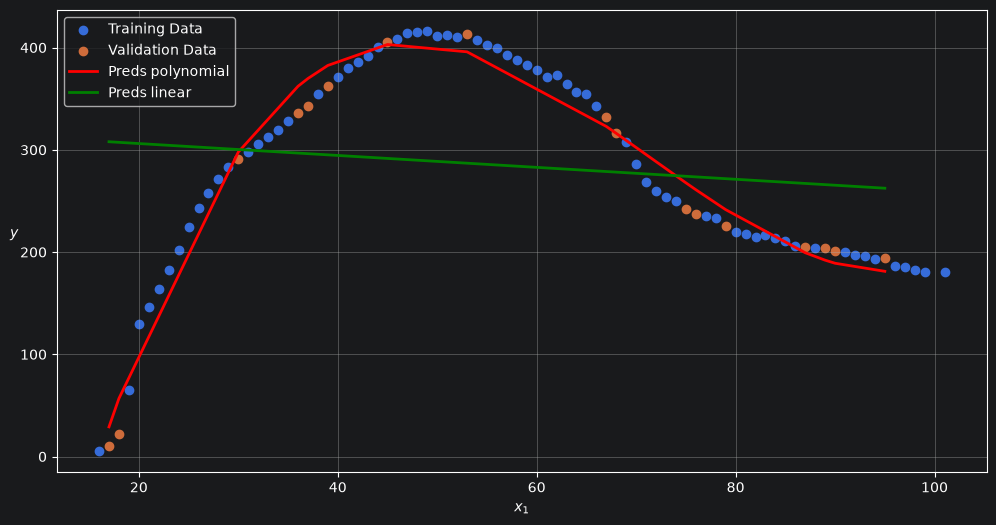

In [123]:
x = train[["age"]].values
y = train[["mean_income"]].values
x_vals = validation[["age"]].values
y_vals = validation[["mean_income"]].values

poly_features = PolynomialFeatures(degree=3, include_bias=False)
X_poly = poly_features.fit_transform(x)

lin_reg1 = LinearRegression()
lin_reg1.fit(x, y)
y_preds_reg = lin_reg1.predict(x_vals)

lin_reg2 = LinearRegression()
lin_reg2.fit(X_poly, y)

X_new_poly = poly_features.transform(x_vals)
y_preds_poly = lin_reg.predict(X_new_poly)

plt.figure(figsize=(12, 6))
plt.scatter(x, y, label="Training Data")
plt.scatter(x_vals, y_vals, label="Validation Data")
plt.plot(x_vals, y_preds_poly, "r-", linewidth=2, label="Preds polynomial")
plt.plot(x_vals, y_preds_reg, "g-", linewidth=2, label="Preds linear")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.legend(loc="upper left")
plt.grid()
plt.show()